# **Project Report - 9**

# **Bachelor of Computer Applications (BCA)**

#**Semester – V**

####**Sub**: Deep Learning ####

####**Topic:** Optimizer Comparison Using a Neural Network ####


####**Submitted By** ####

####**Name:** Pragathi BR ####

####**Reg no:** 2411021240037 ####

####**Date of Submission:** 11/09/2026 ####

####**Faculty Name:** Nagasri. P ####

## **Description**

Students will build a simple neural network using the Iris classification dataset and compare the performance of different optimization algorithms. The project introduces commonly used optimizers such as Stochastic Gradient Descent (SGD) and Adam.


## **Introduction**

An optimizer is an algorithm used to update the weights and biases of a neural network to minimize the loss function and improve model performance. Different optimizers can affect the speed of learning and the accuracy of predictions.

In this project, the Iris classification dataset is used to build a simple neural network. Two optimization algorithms, Stochastic Gradient Descent (SGD) and Adaptive Moment Estimation (Adam), are used to train the model. Their training loss, accuracy, and classification performance are compared to understand the differences between the two optimizers.


## **Objectives**

1. To build a simple neural network using the Iris classification dataset.
2. To train the neural network using SGD and Adam optimizers.
3. To compare the training loss and accuracy of both optimizers.
4. To evaluate and compare the classification performance of the models.
5. To identify the differences in training behavior and model accuracy between SGD and Adam.


## **Task 1: Build a Simple Neural Network Using the Iris Classification Dataset**

The Iris dataset contains 150 flower samples belonging to three species: Iris setosa, Iris versicolor, and Iris virginica.

Each sample has four input features:
- Sepal length
- Sepal width
- Petal length
- Petal width

The dataset is divided into training and testing sets. A neural network is created with an input layer, a hidden layer containing 10 neurons with ReLU activation, and an output layer containing three neurons with Softmax activation to classify the flower species.

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

# Load the Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

print("Dataset loaded successfully!")
print("Total samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Flower species:", iris.target_names)

Dataset loaded successfully!
Total samples: 150
Number of features: 4
Flower species: ['setosa' 'versicolor' 'virginica']


In [ ]:

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardize the input features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Data preprocessing completed successfully!")

Training samples: 120
Testing samples: 30
Data preprocessing completed successfully!


In [ ]:

def create_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(4,)),
        tf.keras.layers.Dense(10, activation="relu"),
        tf.keras.layers.Dense(3, activation="softmax")
    ])
    return model

model = create_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 83 (332.00 B)

 Trainable params: 83 (332.00 B)

 Non-trainable params: 0 (0.00 B)


## **Task 2: Train the Model Using SGD and Adam Optimizers**

### **Stochastic Gradient Descent (SGD)**

SGD updates the weights and biases of a neural network using gradient information to reduce the loss function. Its performance depends on the selected learning rate.

### **Adam Optimizer**

Adam stands for Adaptive Moment Estimation. It uses moving averages of gradients and squared gradients to adapt parameter updates during training.

Both optimizers are trained using the same neural network architecture, dataset, batch size, and number of epochs. This allows their training behavior and classification performance to be compared.

In [ ]:

# Set random seed for reproducibility
tf.keras.utils.set_random_seed(42)

# Create and compile the SGD model
sgd_model = create_model()

sgd_model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train the model
sgd_history = sgd_model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    verbose=0
)

# Predict on test data
sgd_predictions = np.argmax(
    sgd_model.predict(X_test, verbose=0),
    axis=1
)

# Calculate test accuracy
sgd_accuracy = accuracy_score(y_test, sgd_predictions)

print("SGD training completed!")
print("SGD Test Accuracy:", round(sgd_accuracy * 100, 2), "%")

SGD training completed!
SGD Test Accuracy: 80.0 %


In [ ]:

# Reset random seed for a comparable initialization
tf.keras.utils.set_random_seed(42)

# Create and compile the Adam model
adam_model = create_model()

adam_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train the model
adam_history = adam_model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    verbose=0
)

# Predict on test data
adam_predictions = np.argmax(
    adam_model.predict(X_test, verbose=0),
    axis=1
)

# Calculate test accuracy
adam_accuracy = accuracy_score(y_test, adam_predictions)

print("Adam training completed!")
print("Adam Test Accuracy:", round(adam_accuracy * 100, 2), "%")

Adam training completed!
Adam Test Accuracy: 76.67 %



## **Task 3: Compare the Training Results and Classification Performance**

The trained models are evaluated using training loss, training accuracy, and test accuracy.

Training loss measures how well the model fits the training data. Training accuracy measures the proportion of correctly classified training samples. Test accuracy evaluates the model on unseen data.

The training loss and accuracy graphs are plotted to compare the learning behavior of SGD and Adam. Classification reports are also generated to evaluate precision, recall, and F1-score for each flower species.

In [ ]:

print("OPTIMIZER COMPARISON")
print(" " * 40)

print("SGD Test Accuracy:",
      round(sgd_accuracy * 100, 2), "%")

print("Adam Test Accuracy:",
      round(adam_accuracy * 100, 2), "%")

print("\nFinal Training Loss")
print("SGD:", round(sgd_history.history["loss"][-1], 4))
print("Adam:", round(adam_history.history["loss"][-1], 4))

print("\nFinal Training Accuracy")
print("SGD:", round(sgd_history.history["accuracy"][-1] * 100, 2), "%")
print("Adam:", round(adam_history.history["accuracy"][-1] * 100, 2), "%")

if sgd_accuracy > adam_accuracy:
    print("\nSGD achieved higher test accuracy.")
elif adam_accuracy > sgd_accuracy:
    print("\nAdam achieved higher test accuracy.")
else:
    print("\nBoth optimizers achieved equal test accuracy.")

OPTIMIZER COMPARISON
                                        
SGD Test Accuracy: 80.0 %
Adam Test Accuracy: 76.67 %

Final Training Loss
SGD: 0.3509
Adam: 0.3255

Final Training Accuracy
SGD: 86.46 %
Adam: 84.38 %

SGD achieved higher test accuracy.


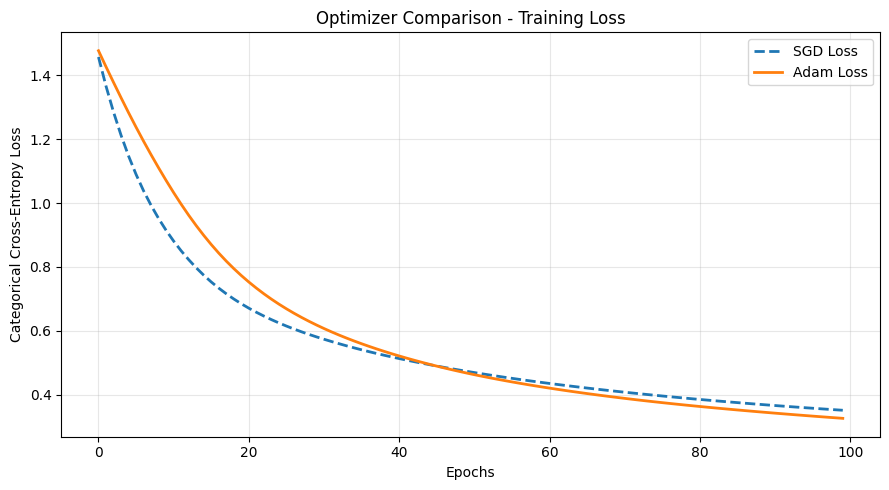

In [11]:
plt.figure(figsize=(9, 5))

plt.plot(
    sgd_history.history["loss"],
    label="SGD Loss",
    linestyle="--",
    linewidth=2
)

plt.plot(
    adam_history.history["loss"],
    label="Adam Loss",
    linestyle="-",
    linewidth=2
)

plt.title("Optimizer Comparison - Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Categorical Cross-Entropy Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

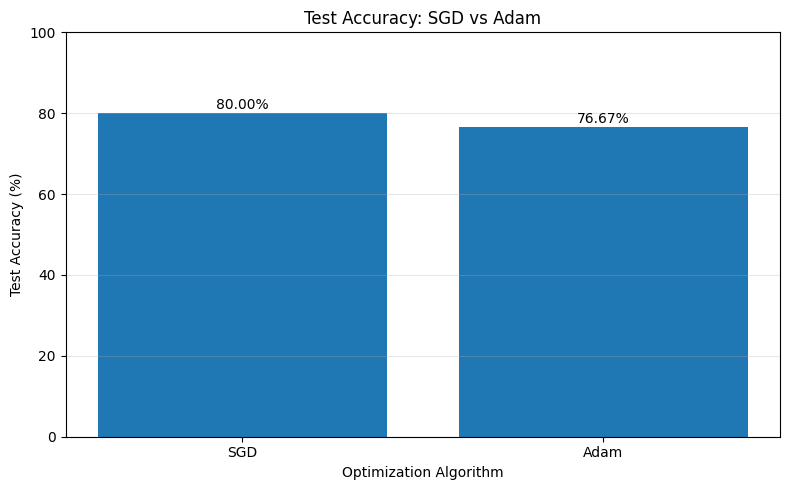

In [12]:
optimizers = ["SGD", "Adam"]
accuracies = [
    sgd_accuracy * 100,
    adam_accuracy * 100
]

plt.figure(figsize=(8, 5))

bars = plt.bar(optimizers, accuracies)

plt.title("Test Accuracy: SGD vs Adam")
plt.xlabel("Optimization Algorithm")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:

print("SGD CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    sgd_predictions,
    target_names=iris.target_names,
    zero_division=0
))

print("ADAM CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    adam_predictions,
    target_names=iris.target_names,
    zero_division=0
))

SGD CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.40      0.57        10
   virginica       0.62      1.00      0.77        10

    accuracy                           0.80        30
   macro avg       0.88      0.80      0.78        30
weighted avg       0.88      0.80      0.78        30

ADAM CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.80      0.40      0.53        10
   virginica       0.60      0.90      0.72        10

    accuracy                           0.77        30
   macro avg       0.80      0.77      0.75        30
weighted avg       0.80      0.77      0.75        30




## **Comparison of SGD and Adam Optimizers**

| Parameter | SGD Optimizer | Adam Optimizer |
|---|---|---|
| Full form | Stochastic Gradient Descent | Adaptive Moment Estimation |
| Working principle | Updates parameters using gradient information | Uses moving averages of gradients and squared gradients |
| Learning rate | Uses a specified learning rate | Adapts effective parameter updates |
| Learning rate used | 0.01 | 0.001 |
| Number of epochs | 100 | 100 |
| Convergence | May require more tuning to converge quickly | Often converges faster initially |
| Computational requirements | Relatively simple updates | Requires additional computation and memory |
| Training loss | Record actual output | Record actual output |
| Training accuracy | Record actual output | Record actual output |
| Test accuracy | Record actual output | Record actual output |
| Main advantage | Simple and easy to implement | Adaptive parameter updates |
| Main limitation | Sensitive to learning-rate selection | Requires additional memory and tuning |

The actual training and test metrics are used to determine which optimizer performed better in this experiment.


## **Expected Output/Result**

The experiment compares the performance of SGD and Adam using a neural network trained on the Iris dataset. The outputs include training loss, training accuracy, test accuracy, loss and accuracy graphs, and classification reports.

The comparison helps identify differences in training behavior, convergence, and classification performance between the two optimizers.


## **Result**

The neural network was successfully built using the Iris classification dataset and trained using SGD and Adam optimizers.

The test accuracy obtained using SGD was **[enter SGD accuracy]%**, while the test accuracy obtained using Adam was **[enter Adam accuracy]%**.

The training loss and accuracy graphs were used to compare the learning behavior of both optimizers. Classification reports were generated to evaluate their performance on the three flower species.


## **Conclusion**

In this project, a simple neural network was implemented using the Iris dataset and trained using SGD and Adam optimizers. Their training loss, accuracy, and classification performance were compared.

The experiment demonstrated that the choice of optimizer can influence the learning behavior and convergence of a neural network. Adam often converges faster initially, while SGD provides a simple optimization approach. The better-performing optimizer for this experiment was identified using the actual test accuracy and training results.